# Overlap repair

A robot body is a tree of modules, and nothing in the tree stops two modules that are not neighbours from growing into the same space. `construct_mjspec_from_graph(graph, repair_overlaps=True)` removes such modules before it builds the body. It finds every pair of modules that penetrate each other deeper than 1% of the thinnest side of the smaller one (Trimesh and python-fcl do the collision test), takes the deeper module of the pair in the tree, and cuts it off with everything attached beyond it, deepest first.

In this notebook you build a small body whose arm folds back into the core, find its overlaps, repair it, look at the body before and after with a sketch drawn from the geoms (no OpenGL needed), read the debug line the repair logs, and count the overlaps in 30 random bodies with and without the repair.

In [1]:
# Standard library
import logging
import random

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import networkx as nx
import numpy as np
from matplotlib.collections import PolyCollection
from rich.table import Table

In [3]:
# Local libraries
from ariel import console
from ariel.body_phenotypes import (
    construct_mjspec_from_graph,
    find_overlaps,
    repair_overlaps,
)
from ariel.body_phenotypes.robogen_lite.overlap import owner_of
from ariel.ec.genotypes.tree import random_tree

In [4]:
# Settings (nothing here is random except random_tree, seeded below)
SEED = 42
BODIES = 30
MODULES = 20
REMOVALS = 2  # modules the repair cuts off the hand-built body

## A body that folds back into itself

The graph has the core (node 0), a brick on its FRONT face, a brick on top of that brick and a hinge on the left of the second brick. Every module is turned 45 degrees, so the second brick and the hinge swing back into the core's space. Node 1 is the core's neighbour, so it is never compared with it.

In [5]:
NODES = {
    0: ("CORE", "DEG_0"),
    1: ("BRICK", "DEG_45"),
    2: ("BRICK", "DEG_45"),
    3: ("HINGE", "DEG_45"),
}
EDGES = [(0, 1, "FRONT"), (1, 2, "TOP"), (2, 3, "LEFT")]
graph = nx.DiGraph()
for node, (kind, rotation) in NODES.items():
    graph.add_node(node, type=kind, rotation=rotation)
for parent, child, face in EDGES:
    graph.add_edge(parent, child, face=face)
console.print(f"{len(graph)} modules, edges {list(graph.edges)}")

4 modules, edges [(0, 1), (1, 2), (2, 3)]

In [6]:
found = find_overlaps(graph, construct_mjspec_from_graph(graph))
table = Table(title="Overlapping pairs")
for column in ("first", "second", "depth (mm)", "tolerance (mm)"):
    table.add_column(column, justify="right")
for overlap in found:
    table.add_row(
        str(overlap.first),
        str(overlap.second),
        f"{1000 * overlap.depth:.2f}",
        f"{1000 * overlap.tolerance:.2f}",
    )
console.print(table)

               Overlapping pairs                
┏━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ first ┃ second ┃ depth (mm) ┃ tolerance (mm) ┃
┡━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│     0 │      2 │      20.71 │           1.00 │
│     0 │      3 │      56.63 │           0.40 │
└───────┴────────┴────────────┴────────────────┘

## Repair it

`repair_overlaps(graph, build)` takes the graph and the function that builds a body from it, and returns a pruned copy; the graph you pass in is left alone. Each removal is logged on one debug line, which the handler below collects.

In [7]:
class Collect(logging.Handler):
    def __init__(self) -> None:
        super().__init__(logging.DEBUG)
        self.lines: list[str] = []

    def emit(self, record: logging.LogRecord) -> None:
        self.lines.append(record.getMessage())


collector = Collect()
logger = logging.getLogger("rich")
level = logger.level
logger.addHandler(collector)
logger.setLevel(logging.DEBUG)
repaired = repair_overlaps(graph, construct_mjspec_from_graph)
logger.setLevel(level)
logger.removeHandler(collector)
for line in collector.lines:
    console.print(line)
console.print(f"kept modules {sorted(repaired.nodes)}")

[13:20:21] DEBUG    pruned 1 modules (ids 3) for overlap with 0                                      ]8;id=530101;file:///home/jmdm/projects/ariel/src/ariel/body_phenotypes/robogen_lite/overlap.py\overlap.py]8;;\:]8;id=669561;file:///home/jmdm/projects/ariel/src/ariel/body_phenotypes/robogen_lite/overlap.py#362\362]8;;\

           DEBUG    pruned 1 modules (ids 2) for overlap with 0                                      ]8;id=634774;file:///home/jmdm/projects/ariel/src/ariel/body_phenotypes/robogen_lite/overlap.py\overlap.py]8;;\:]8;id=90177;file:///home/jmdm/projects/ariel/src/ariel/body_phenotypes/robogen_lite/overlap.py#362\362]8;;\

pruned 1 modules (ids 3) for overlap with 0

pruned 1 modules (ids 2) for overlap with 0

kept modules [0, 1]

## Look at the body before and after

The sketch draws every geom as the six faces of its box, seen from above, in the colour the model gives it. Geoms of modules that take part in an overlap are drawn red. The pruned modules are gone from the second picture.

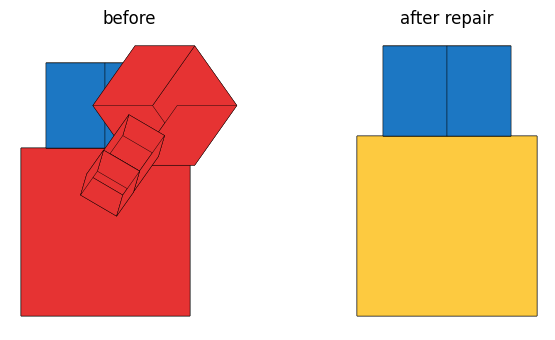

In [8]:
CORNERS = np.array([
    [x, y, z] for x in (-1, 1) for y in (-1, 1) for z in (-1, 1)
])
FACES = [
    [0, 1, 3, 2],
    [4, 5, 7, 6],
    [0, 1, 5, 4],
    [2, 3, 7, 6],
    [0, 2, 6, 4],
    [1, 3, 7, 5],
]


def sketch(body_graph: nx.DiGraph, axis: plt.Axes) -> None:
    core = construct_mjspec_from_graph(body_graph)
    model = core.spec.compile()
    data = mujoco.MjData(model)
    mujoco.mj_forward(model, data)
    clashing = {
        node
        for overlap in find_overlaps(body_graph, core)
        for node in (overlap.first, overlap.second)
    }
    faces, colours = [], []
    for geom in range(model.ngeom):
        rotation = data.geom_xmat[geom].reshape(3, 3)
        corners = (
            data.geom_xpos[geom]
            + (CORNERS * model.geom_size[geom]) @ rotation.T
        )
        faces += [corners[face][:, :2] for face in FACES]
        red = owner_of(model, geom) in clashing
        colours += [
            (0.9, 0.2, 0.2, 1.0) if red else model.geom_rgba[geom]
        ] * len(FACES)
    axis.add_collection(
        PolyCollection(
            faces, facecolors=colours, edgecolors="k", linewidths=0.3
        )
    )
    axis.autoscale()
    axis.set_aspect("equal")
    axis.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for axis, (title, body_graph) in zip(
    axes, (("before", graph), ("after repair", repaired)), strict=True
):
    sketch(body_graph, axis)
    axis.set_title(title)
plt.tight_layout()
plt.show()

## Bodies that do not overlap stay the same

The flag is off by default, and with it on a body with no overlap gives exactly the same MuJoCo description, byte for byte. A short chain along the FRONT faces is such a body.

In [9]:
chain = nx.DiGraph()
chain.add_node(0, type="CORE", rotation="DEG_0")
chain.add_node(1, type="BRICK", rotation="DEG_0")
chain.add_node(2, type="HINGE", rotation="DEG_90")
chain.add_edge(0, 1, face="FRONT")
chain.add_edge(1, 2, face="FRONT")
plain = construct_mjspec_from_graph(chain).spec.to_xml()
with_repair = construct_mjspec_from_graph(chain, repair_overlaps=True)
same = plain == with_repair.spec.to_xml()
console.print(f"clean body, same XML with the repair: {same}")

clean body, same XML with the repair: True

## Count them in random bodies

`random_tree` draws bodies that were never checked for overlap. The cell below builds 30 of them with up to 20 modules, counts how many have an overlap, repairs each one with the flag, and counts again.

In [10]:
random.seed(SEED)
graphs = [random_tree(MODULES).to_networkx() for _ in range(BODIES)]
before = [
    bool(find_overlaps(g, construct_mjspec_from_graph(g))) for g in graphs
]
fixed = [repair_overlaps(g, construct_mjspec_from_graph) for g in graphs]
after = [bool(find_overlaps(g, construct_mjspec_from_graph(g))) for g in fixed]
removed = sum(len(g) - len(f) for g, f in zip(graphs, fixed, strict=True))
console.print(
    f"overlapping before {sum(before)} of {BODIES}, after {sum(after)}; "
    f"{removed} modules removed in all"
)

overlapping before 27 of 30, after 0; 122 modules removed in all

## Checks

The overlap must be found in the hand-built body, the repair must remove the deeper module of each pair, deepest first, one log line each (and keep the core), and the repaired body must be clean. The input graph must not change, a clean body must be untouched, and no random body may overlap after the repair. `tools/measure_overlap.py` repeats the last count with MuJoCo as an independent check.

In [11]:
assert [(o.first, o.second) for o in found] == [(0, 2), (0, 3)]
assert all(o.depth > o.tolerance for o in found)
assert len(graph) == len(NODES)  # the input is not changed
assert sorted(repaired.nodes) == [
    0,
    1,
]  # 3 and 2 are the deeper modules of (0, 3) and (0, 2)
assert not find_overlaps(repaired, construct_mjspec_from_graph(repaired))
assert len(collector.lines) == REMOVALS  # one line per removal, deepest first
assert "ids 3" in collector.lines[0]
assert "ids 2" in collector.lines[1]
assert same
assert sum(before) > 0  # the sample has something to repair
assert sum(after) == 0
assert removed > 0